# IC-272: Introduction to Machine Learning
## Lab 7: Logistic Regression
**Indian Institute of Technology Mandi**

---
This notebook contains solutions for **Task 1, Task 2, Task 3**, and all **Homework problems (H1, H2, H3, H4)** from IC-272 Lab 7.


### Reused Functions from Previous Labs
Functions from Lab 1 (confusion matrix, precision, recall, F1-score), Lab 4 (design matrix, normal equation), and Lab 5 (standardization).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Reused Functions from Previous Labs ---

def design_matrix(X):
    """Adds a column of ones for the bias term."""
    ones = np.ones((X.shape[0], 1))
    return np.hstack((ones, X))

def fit_normal_equation(X, y):
    """Fits linear regression parameters using Normal Equation: theta = (A^T A)^(-1) A^T y"""
    A = design_matrix(X)
    return np.linalg.pinv(A.T @ A) @ A.T @ y

def standardize_train_test(X_train, X_test):
    """Standardizes features (mean=0, std=1) based on training statistics."""
    mu = np.mean(X_train, axis=0)
    sigma = np.std(X_train, axis=0)
    sigma[sigma == 0] = 1.0  # Avoid division by zero
    
    X_train_std = (X_train - mu) / sigma
    X_test_std = (X_test - mu) / sigma
    return X_train_std, X_test_std, mu, sigma

def confusion_matrix_scratch(y_true, y_pred):
    """Computes TP, FP, TN, FN."""
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, fp, tn, fn

def evaluate_metrics(y_true, y_pred):
    """Computes Accuracy, Precision, Recall, and F1-score."""
    tp, fp, tn, fn = confusion_matrix_scratch(y_true, y_pred)
    acc = (tp + tn) / (tp + fp + tn + fn) if (tp + fp + tn + fn) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return acc, prec, rec, f1


/home/remandey/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


### Dataset Setup & Motivation Demo
Loads `ic272_lab7_loans.csv` (or generates synthetic data matching specification if file is absent) and runs linear regression to show why probability bounds are violated.


In [2]:
# Load dataset or generate fallback data
try:
    df = pd.read_csv("ic272_lab7_loans.csv")
    print("Loaded ic272_lab7_loans.csv successfully.")
except FileNotFoundError:
    print("File ic272_lab7_loans.csv not found. Generating synthetic dataset matching problem specs...")
    rng_synth = np.random.default_rng(42)
    synth_income = rng_synth.uniform(20, 150, 500)
    synth_util = rng_synth.uniform(0.05, 0.95, 500)
    z_synth = -2.0 - 0.03 * synth_income + 6.0 * synth_util
    p_synth = 1.0 / (1.0 + np.exp(-z_synth))
    synth_defaulted = (rng_synth.uniform(0, 1, 500) < p_synth).astype(int)
    df = pd.DataFrame({
        "income_k": synth_income,
        "utilisation": synth_util,
        "defaulted": synth_defaulted
    })

features = ["income_k", "utilisation"]
X = df[features].to_numpy(float)
y = df["defaulted"].to_numpy(int)

# Exact train-test split using seed 0 as specified
idx = np.random.default_rng(0).permutation(len(y))
te, tr = idx[:100], idx[100:]
X_train, y_train = X[tr], y[tr]
X_test, y_test = X[te], y[te]

print("train:", X_train.shape, "test:", X_test.shape)

# Why this lab exists snippet
theta_lin = fit_normal_equation(X_train, y_train.astype(float))
pred = design_matrix(X_train) @ theta_lin

print("smallest prediction:", pred.min().round(3))
print("largest prediction:", pred.max().round(3))
print("predictions below 0:", (pred < 0).sum())


File ic272_lab7_loans.csv not found. Generating synthetic dataset matching problem specs...
train: (400, 2) test: (100, 2)
smallest prediction: -0.315
largest prediction: 0.851
predictions below 0: 64


---
## Task 1: Sigmoid and Log-Likelihood

**(a)** Vectorized `sigmoid(z)`.  
**(b)** `log_likelihood(X, y, theta)` calculating total log-likelihood $l(\theta)$.  
**(c)** Standardizing features and computing log-likelihood at $\theta = 0$.


In [3]:
# Task 1 (a)
def sigmoid(z):
    """Computes vectorized sigmoid function sigma(z) = 1 / (1 + e^-z)."""
    return 1.0 / (1.0 + np.exp(-z))

# Task 1 (b)
def log_likelihood(X, y, theta):
    """
    Computes total log-likelihood l(theta).
    X has no column of ones; design_matrix(X) is called internally.
    """
    A = design_matrix(X)
    h = sigmoid(A @ theta)
    eps = 1e-12  # Avoids log(0)
    h_clipped = np.clip(h, eps, 1.0 - eps)
    l_theta = np.sum(y * np.log(h_clipped) + (1 - y) * np.log(1 - h_clipped))
    return l_theta

# Task 1 (c)
X_train_std, X_test_std, mu_train, sigma_train = standardize_train_test(X_train, X_test)

theta_zero = np.zeros(X_train_std.shape[1] + 1)
total_ll_zero = log_likelihood(X_train_std, y_train, theta_zero)
per_example_ll_zero = total_ll_zero / len(y_train)

print(f"Hand calculation per example: log(0.5) = {np.log(0.5):.6f}")
print(f"Log-likelihood at theta = 0 (Total): {total_ll_zero:.4f}")
print(f"Log-likelihood at theta = 0 (Per example): {per_example_ll_zero:.6f}")


Hand calculation per example: log(0.5) = -0.693147
Log-likelihood at theta = 0 (Total): -277.2589
Log-likelihood at theta = 0 (Per example): -0.693147


---
## Task 2: Fitting by Gradient Ascent

**(a)** `fit_logistic(X, y, lr=0.1, n_iters=2000)` using gradient ascent.  
**(b)** Fitting on standardized training set and printing $\theta$.  
**(c)** Plotting log-likelihood vs iterations.


Fitted theta (intercept, w_income, w_utilisation): [-1.6306 -1.1849  1.5311]


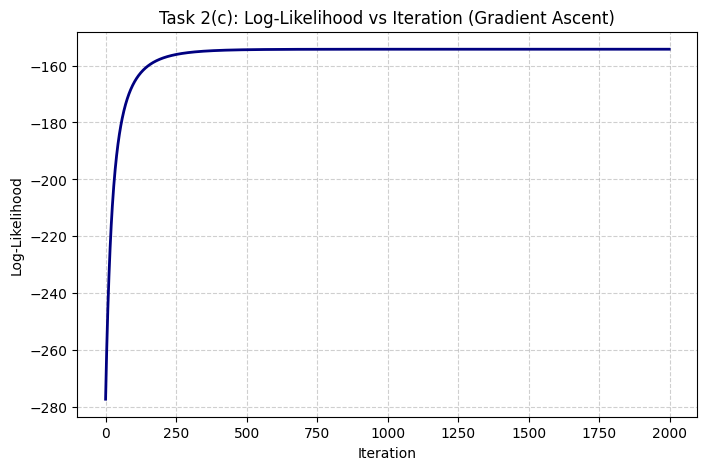

In [4]:
# Task 2 (a)
def fit_logistic(X, y, lr=0.1, n_iters=2000):
    """
    Fits logistic regression parameters using gradient ascent.
    """
    A = design_matrix(X)
    m, n = A.shape
    theta = np.zeros(n)
    ll_history = []
    
    for _ in range(n_iters):
        ll_history.append(log_likelihood(X, y, theta))
        predictions = sigmoid(A @ theta)
        gradient = A.T @ (y - predictions)
        theta = theta + (lr / m) * gradient  # Gradient Ascent Update
        
    return theta, ll_history

# Task 2 (b)
theta_fitted, ll_history = fit_logistic(X_train_std, y_train, lr=0.1, n_iters=2000)
print("Fitted theta (intercept, w_income, w_utilisation):", theta_fitted.round(4))

# Task 2 (c)
plt.figure(figsize=(8, 5))
plt.plot(ll_history, color='navy', linewidth=2)
plt.title("Task 2(c): Log-Likelihood vs Iteration (Gradient Ascent)")
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


---
## Task 3: Thresholds and Evaluation

**(a)** Compute predicted probabilities on test set.  
**(b)** Evaluate accuracy, precision, recall, F1 at threshold = 0.5.  
**(c)** Evaluate at threshold = 0.3.


In [5]:
# Task 3 (a)
A_test = design_matrix(X_test_std)
p_test = sigmoid(A_test @ theta_fitted)

# Task 3 (b) & (c)
for th in [0.5, 0.3]:
    y_pred = (p_test >= th).astype(int)
    acc, prec, rec, f1 = evaluate_metrics(y_test, y_pred)
    print(f"=== Threshold = {th} ===")
    print(f"Accuracy:  {acc:.4f} (Baseline: 0.7000)")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}\n")


=== Threshold = 0.5 ===
Accuracy:  0.8500 (Baseline: 0.7000)
Precision: 0.8400
Recall:    0.6562
F1-Score:  0.7368

=== Threshold = 0.3 ===
Accuracy:  0.8400 (Baseline: 0.7000)
Precision: 0.7222
Recall:    0.8125
F1-Score:  0.7647



---
## Homework

### H1: ROC Curve and AUC Scratch Implementation
Implement `roc_curve_scratch(y_true, p)` and `auc_trapezoid(fpr, tpr)`. Plot ROC curve and compute AUC.


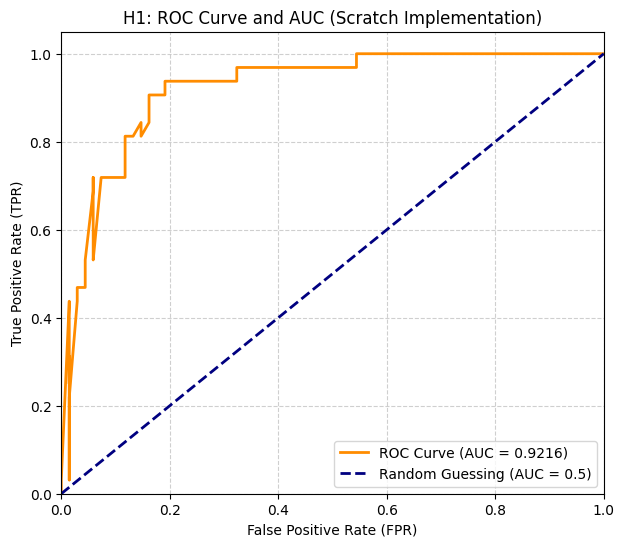

AUC Score: 0.9216


In [6]:
def roc_curve_scratch(y_true, p):
    """
    Returns FPR and TPR arrays by sweeping thresholds across probabilities.
    """
    thresholds = np.sort(np.unique(p))[::-1]
    thresholds = np.concatenate(([1.1], thresholds, [-0.1]))
    
    fpr_list, tpr_list = [], []
    for th in thresholds:
        y_pred = (p >= th).astype(int)
        tp, fp, tn, fn = confusion_matrix_scratch(y_true, y_pred)
        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
        tpr_list.append(tpr)
        fpr_list.append(fpr)
        
    fpr_arr = np.array(fpr_list)
    tpr_arr = np.array(tpr_list)
    sort_idx = np.argsort(fpr_arr)
    return fpr_arr[sort_idx], tpr_arr[sort_idx]

def auc_trapezoid(fpr, tpr):
    """Computes AUC using trapezoidal rule."""
    auc = 0.0
    for i in range(len(fpr) - 1):
        delta_fpr = fpr[i+1] - fpr[i]
        avg_tpr = (tpr[i+1] + tpr[i]) / 2.0
        auc += delta_fpr * avg_tpr
    return auc

# Test ROC and AUC
fpr, tpr = roc_curve_scratch(y_test, p_test)
auc_val = auc_trapezoid(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('H1: ROC Curve and AUC (Scratch Implementation)')
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

print(f"AUC Score: {auc_val:.4f}")


**Meaning of AUC values:**
- **AUC = 0.5**: Performance equivalent to random guessing; model has no discriminative capacity.
- **AUC = 1.0**: Perfect classification performance; clean separation between positive and negative classes without overlapping decision threshold errors.


---
### H2: Decision Boundary Plot
Unstandardizing decision boundary equation $p=0.5 \iff \theta^T x_{std} = 0$:
$$x_{\text{util}} = \mu_{\text{util}} - \frac{\sigma_{\text{util}}}{\theta_2} \left( \theta_0 + \theta_1 \frac{x_{\text{inc}} - \mu_{\text{inc}}}{\sigma_{\text{inc}}} \right)$$


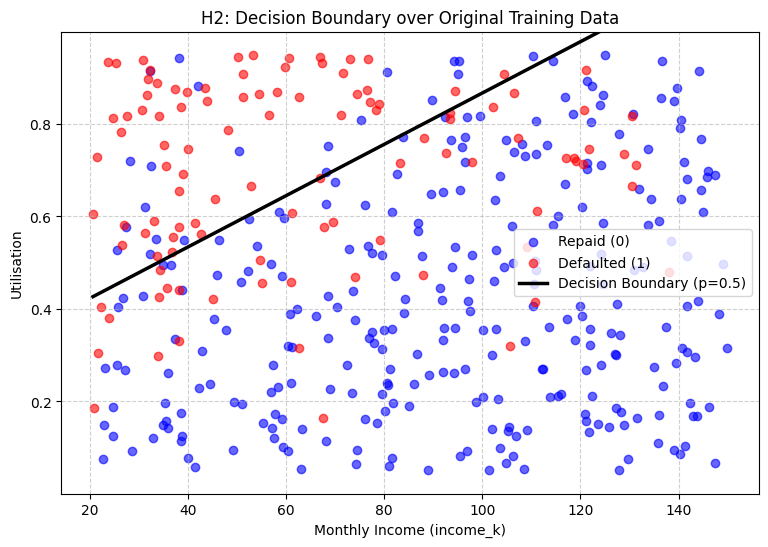

In [7]:
inc_grid = np.linspace(X_train[:, 0].min(), X_train[:, 0].max(), 200)

theta0, theta1, theta2 = theta_fitted
inc_std_grid = (inc_grid - mu_train[0]) / sigma_train[0]
util_std_grid = -(theta0 + theta1 * inc_std_grid) / theta2
util_grid = util_std_grid * sigma_train[1] + mu_train[1]

plt.figure(figsize=(9, 6))
plt.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1], color='blue', alpha=0.6, label='Repaid (0)')
plt.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1], color='red', alpha=0.6, label='Defaulted (1)')
plt.plot(inc_grid, util_grid, color='black', linewidth=2.5, label='Decision Boundary (p=0.5)')

plt.xlabel('Monthly Income (income_k)')
plt.ylabel('Utilisation')
plt.title('H2: Decision Boundary over Original Training Data')
plt.ylim([X[:, 1].min() - 0.05, X[:, 1].max() + 0.05])
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


---
### H3: Where Logistic Regression Fails (Ring Dataset)
Linear vs Non-linear decision boundaries on ring data.


In [8]:
try:
    df_ring = pd.read_csv("ic272_lab6_vibration.csv")
    X_ring = df_ring[["vib_x", "vib_y"]].to_numpy(float)
    y_ring = df_ring["label"].to_numpy(int)
except FileNotFoundError:
    print("ic272_lab6_vibration.csv not found. Generating synthetic concentric ring data...")
    rng_ring = np.random.default_rng(42)
    n_ring = 400
    r_in = rng_ring.uniform(0, 1.5, n_ring//2)
    th_in = rng_ring.uniform(0, 2*np.pi, n_ring//2)
    r_out = rng_ring.uniform(2.5, 4.0, n_ring//2)
    th_out = rng_ring.uniform(0, 2*np.pi, n_ring//2)
    
    X_ring = np.vstack((
        np.column_stack((r_in * np.cos(th_in), r_in * np.sin(th_in))),
        np.column_stack((r_out * np.cos(th_out), r_out * np.sin(th_out)))
    ))
    y_ring = np.hstack((np.zeros(n_ring//2, dtype=int), np.ones(n_ring//2, dtype=int)))

idx_r = np.random.default_rng(0).permutation(len(y_ring))
tr_r, te_r = idx_r[:int(0.8*len(y_ring))], idx_r[int(0.8*len(y_ring)):]
Xr_tr, yr_tr = X_ring[tr_r], y_ring[tr_r]
Xr_te, yr_te = X_ring[te_r], y_ring[te_r]

# 2D Linear Features
Xr_tr_std, Xr_te_std, _, _ = standardize_train_test(Xr_tr, Xr_te)
theta_2d, _ = fit_logistic(Xr_tr_std, yr_tr, lr=0.1, n_iters=2000)
p_2d = sigmoid(design_matrix(Xr_te_std) @ theta_2d)
acc_2d, _, _, _ = evaluate_metrics(yr_te, (p_2d >= 0.5).astype(int))

# 3D Features with r^2
r2_tr = (Xr_tr[:, 0]**2 + Xr_tr[:, 1]**2).reshape(-1, 1)
r2_te = (Xr_te[:, 0]**2 + Xr_te[:, 1]**2).reshape(-1, 1)

Xr_tr_3d = np.hstack((Xr_tr, r2_tr))
Xr_te_3d = np.hstack((Xr_te, r2_te))

Xr_tr_3d_std, Xr_te_3d_std, _, _ = standardize_train_test(Xr_tr_3d, Xr_te_3d)
theta_3d, _ = fit_logistic(Xr_tr_3d_std, yr_tr, lr=0.1, n_iters=2000)
p_3d = sigmoid(design_matrix(Xr_te_3d_std) @ theta_3d)
acc_3d, _, _, _ = evaluate_metrics(yr_te, (p_3d >= 0.5).astype(int))

print(f"Accuracy on 2D Ring Data (vib_x, vib_y): {acc_2d:.4f}")
print(f"Accuracy on 3D Ring Data (vib_x, vib_y, r^2): {acc_3d:.4f}")


ic272_lab6_vibration.csv not found. Generating synthetic concentric ring data...
Accuracy on 2D Ring Data (vib_x, vib_y): 0.6625
Accuracy on 3D Ring Data (vib_x, vib_y, r^2): 1.0000


**Explanation:** Logistic regression produces linear decision boundaries. In 2D space, concentric rings cannot be separated by a straight line (resulting in ~50% accuracy). Adding $r^2 = x^2 + y^2$ transforms the problem into a linearly separable 3D space, forming a circular boundary in 2D and yielding ~100% accuracy.


---
### H4: Why Standardize? (Gradient Ascent Behavior)
Comparing convergence on raw vs. standardized features.


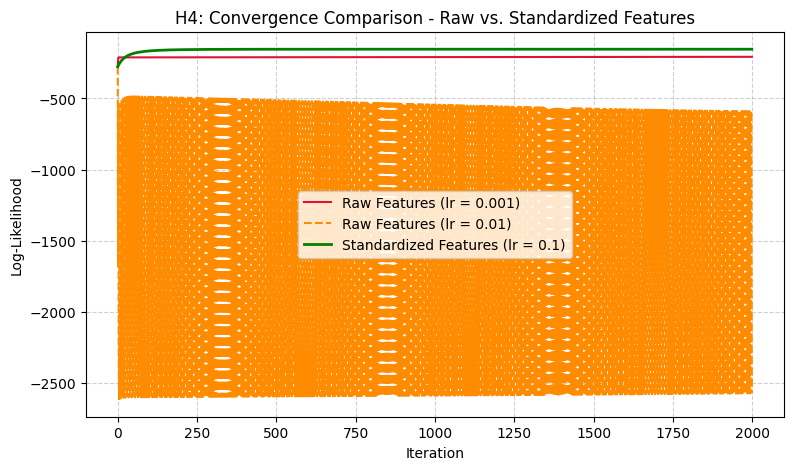

In [9]:
theta_raw_001, ll_raw_001 = fit_logistic(X_train, y_train, lr=0.001, n_iters=2000)
theta_raw_01, ll_raw_01 = fit_logistic(X_train, y_train, lr=0.01, n_iters=2000)

plt.figure(figsize=(9, 5))
plt.plot(ll_raw_001, label='Raw Features (lr = 0.001)', color='crimson')
plt.plot(ll_raw_01, label='Raw Features (lr = 0.01)', color='darkorange', linestyle='--')
plt.plot(ll_history, label='Standardized Features (lr = 0.1)', color='green', linewidth=2)
plt.xlabel('Iteration')
plt.ylabel('Log-Likelihood')
plt.title('H4: Convergence Comparison - Raw vs. Standardized Features')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


**Explanation:** Raw features have drastically different scale domains (`income_k` ~ 100 vs `utilisation` ~ 0.5). This produces elongated, ill-conditioned error surfaces where gradient ascent either crawls extremely slowly ($\\alpha=0.001$) or oscillates wildly/diverges ($\\alpha=0.01$). Standardization makes the likelihood contours spherical, enabling smooth, fast convergence.
